In [21]:
import pandas as pd

# encoding_errors='ignore' : 에러가 나는 글자는 무시하고 강제로 읽어오는 마법의 명령어입니다!
df = pd.read_csv('changwon_weather.csv', encoding='cp949', encoding_errors='ignore')

# 데이터 잘 들어왔는지 5줄 확인
df.head()

,占쏙옙占쏙옙,占쏙옙占쏙옙占쏙옙,占싹쏙옙,占쏙옙欄占쏙옙(占쏙옙C),占쏙옙占쏙옙占쏙옙占(占쏙옙C),占쌍곤옙占쏙옙占(占쏙옙C),占싹곤옙占쏙옙占쏙옙(mm)
0,155,창占쏙옙,2026-01-01,-2.6,-4.5,0.1,NaN
1,155,창占쏙옙,2026-01-02,-2.9,-7.5,1.2,NaN
2,155,창占쏙옙,2026-01-03,-0.3,-4.8,5.3,NaN
3,155,창占쏙옙,2026-01-04,3.6,-2.1,9.6,NaN
4,155,창占쏙옙,2026-01-05,4.1,-0.1,9.1,NaN


In [23]:
# 1. 외계어로 깨진 7개 칸의 이름을 우리가 알아보기 쉽게 덮어씌웁니다.
df.columns = ['지점번호', '지점명', '날짜', '평균기온', '최저기온', '최고기온', '강수량']

# 2. 분석에 필요 없는 '지점번호'와 '지점명' 칸은 아예 삭제해서 표를 깔끔하게 만듭니다.
df = df.drop(['지점번호', '지점명'], axis=1)

# 3. 예뻐진 데이터 5줄 다시 확인!
df.head()

,날짜,평균기온,최저기온,최고기온,강수량
0,2026-01-01,-2.6,-4.5,0.1,NaN
1,2026-01-02,-2.9,-7.5,1.2,NaN
2,2026-01-03,-0.3,-4.8,5.3,NaN
3,2026-01-04,3.6,-2.1,9.6,NaN
4,2026-01-05,4.1,-0.1,9.1,NaN


In [24]:
# 1. '날짜' 칸을 진짜 달력(datetime) 형식으로 변환하기
df['날짜'] = pd.to_datetime(df['날짜'])

# 2. 날짜에서 '월(month)'만 쏙 뽑아서 새로운 칸 만들기
df['월'] = df['날짜'].dt.month

# 3. '월'별로 끼리끼리 묶어서 '평균기온'의 평균 구하기
monthly_temp = df.groupby('월')['평균기온'].mean()

# 4. 결과 확인하기!
print(monthly_temp)

월
1      2.067742
2      5.992857
3      9.832258
4     15.603333
5     19.496774
6     22.710000
7     27.861290
8     28.548387
9     23.736667
10    19.550000
Name: 평균기온, dtype: float64


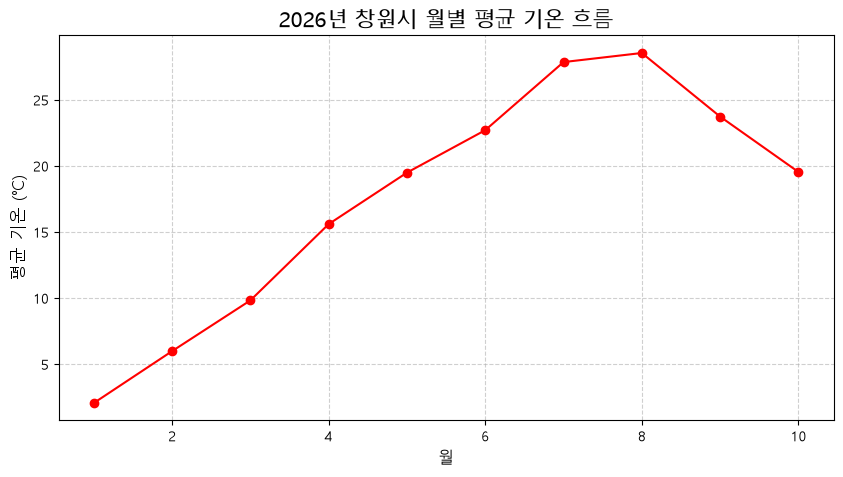

In [27]:
# 1. 그림 그리기 도구 불러오기
import matplotlib.pyplot as plt

# 2. 한글 폰트 깨짐 방지 설정 (윈도우용 '맑은 고딕')
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False # 마이너스(-) 기호 깨짐 방지

# 3. 그래프 크기 설정
plt.figure(figsize=(10, 5))

# 4. 꺾은선 그래프 그리기 (x축: 월, y축: 평균기온, 마커(o) 표시)
plt.plot(monthly_temp.index, monthly_temp.values, marker='o', color='red', linestyle='-')

# 5. 그래프에 제목과 이름표 달기
plt.title('2026년 창원시 월별 평균 기온 흐름', fontsize=15)
plt.xlabel('월', fontsize=12)
plt.ylabel('평균 기온 (℃)', fontsize=12)

# 6. 눈금선(그리드) 추가해서 보기 쉽게 만들기
plt.grid(True, linestyle='--', alpha=0.6)

# 7. 그래프 짠! 하고 보여주기
plt.show()

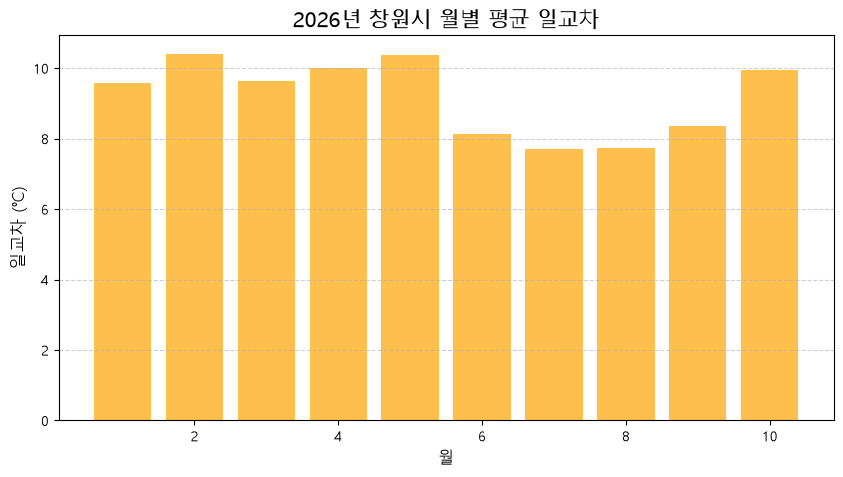

In [29]:
# 1. 그래프 크기 설정
plt.figure(figsize=(10, 5))

# 2. 막대 그래프 그리기 (x축: 월, y축: 일교차, 색상: 오렌지색)
# plt.plot 대신 plt.bar를 사용합니다!
plt.bar(monthly_range.index, monthly_range.values, color='orange', alpha=0.7)

# 3. 그래프에 제목과 이름표 달기
plt.title('2026년 창원시 월별 평균 일교차', fontsize=15)
plt.xlabel('월', fontsize=12)
plt.ylabel('일교차 (℃)', fontsize=12)

# 4. 눈금선 추가 (y축 가로선만 표시해서 깔끔하게)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# 5. 그래프 보여주기
plt.show()

In [30]:
# 1. 월별 강수량 총합 구하기 (mean 대신 sum을 사용합니다!)
monthly_rain = df.groupby('월')['강수량'].sum()

# 2. 결과 확인하기
print("☔ 2026년 창원시 월별 총 강수량 (mm) ☔")
print(monthly_rain)

☔ 2026년 창원시 월별 총 강수량 (mm) ☔
월
1       0.1
2      32.5
3      61.6
4     132.2
5     147.0
6     107.1
7      63.4
8     400.9
9      60.7
10      0.0
Name: 강수량, dtype: float64


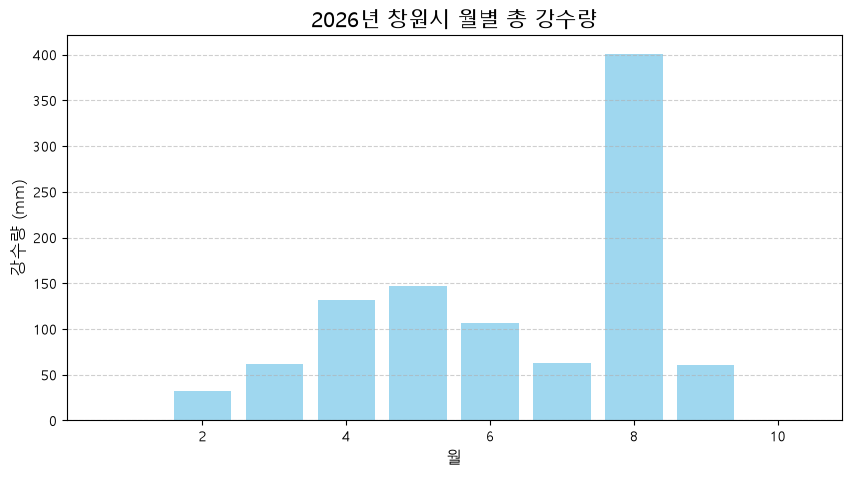

In [31]:
# 1. 그래프 크기 설정
plt.figure(figsize=(10, 5))

# 2. 막대 그래프 그리기 (x축: 월, y축: 강수량, 색상: 하늘색)
plt.bar(monthly_rain.index, monthly_rain.values, color='skyblue', alpha=0.8)

# 3. 그래프에 제목과 이름표 달기
plt.title('2026년 창원시 월별 총 강수량', fontsize=15)
plt.xlabel('월', fontsize=12)
plt.ylabel('강수량 (mm)', fontsize=12)

# 4. 눈금선 추가 (가로선)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# 5. 그래프 보여주기
plt.show()

In [28]:
# 1. '일교차'라는 새로운 칸 만들기 (공식: 최고기온 - 최저기온)
df['일교차'] = df['최고기온'] - df['최저기온']

# 2. 월별로 '일교차'의 평균 구하기 (어느 달이 평균적으로 일교차가 큰지 확인)
monthly_range = df.groupby('월')['일교차'].mean()

# 3. 결과 확인하기
print("🌡️ 창원시 월별 평균 일교차 🌡️")
print(monthly_range)

🌡️ 창원시 월별 평균 일교차 🌡️
월
1      9.590323
2     10.407143
3      9.648387
4     10.003333
5     10.367742
6      8.143333
7      7.712903
8      7.729032
9      8.356667
10     9.937500
Name: 일교차, dtype: float64


In [26]:
# 그래프 그리기 도구(matplotlib) 설치하기
%pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 9.5/9.5 MB 59.2 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 48.9 MB/s  0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------- 7.2/7.2 MB 38.9 MB/s  0:00:00

   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----------------- ---------------------- 3/7 [fonttools]
   ----------------- ---------------------- 3/7 [fonttools]
   ----------------- ---------------------- 3/7 [fonttools]
   ----------------- ---------------------- 3/7 [fonttools]
   ----------------- ---------------------- 3/7 [fonttools]
   ---------------------------------- ----- 6/7 [matplotlib]
   ---------------------------------- ----- 6/7 [matplotlib]
   -------------------------------

In [2]:
%pip install pandas

   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   ---------------------------------------- 9.8/9.8 MB 59.1 MB/s  0:00:00
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------------------------------------  12.6/12.7 MB 65.4 MB/s eta 0:00:01
   ---------------------------------------- 12.7/12.7 MB 60.1 MB/s  0:00:00

   ---------------------------------------- 0/3 [tzdata]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   -------------------------- ------------- 2/3 [pandas]
   ----------